# Ghost physicians in Medicaid, 2018 to 2024

**Extending a 2026 Health Affairs study from three years to seven, with the public T-MSIS extracts and a monthly history of NPPES.**

Zhu, Johnston, Hart, Polsky and McConnell ("Quarter of physicians enrolled in Medicaid delivered no care to beneficiaries in 2021", *Health Affairs* 45(2), February 2026) linked Medicaid provider enrollment files to Medicaid claims for 2019 to 2021. They found that 27.7 percent of physicians enrolled in Medicaid in five specialties saw no Medicaid patient in 2021, and called them *ghost* physicians. Psychiatry was worst at 43 percent. The study used the restricted T-MSIS Analytic Files under a data use agreement, and it ends on the limits of its denominator: NPPES "does not confirm current clinical activity", and "some physicians may have retired, relocated, or shifted to nonclinical roles while maintaining an active NPI, which could have modestly inflated the denominator". It also excluded 21 of 153 state-years for data quality, and could not use data after 2021.

Two things changed in 2026. HHS published provider-level extracts of T-MSIS on [opendata.hhs.gov](https://opendata.hhs.gov/): every provider enrollment segment by state from 2018 to 2024, and paid claims by provider, HCPCS code and month. And this repository turns every monthly NPPES file since 2007 into one panel, so the study's NPPES denominator can be rebuilt for every year from the same monthly series. With those two sources the notebook can:

1. extend the study's enrollment table (its Exhibit 1) from 2019-2021 to 2018-2024,
2. show how much the enrollment denominator depends on which states put NPIs on their records,
3. say what the public spending extract can and cannot show about the study's participation tiers, given its suppression floor.

Each step follows the study's own definitions where the paper states them. Where it does not (the specialty codes and the excluded state-years are in its paywalled appendix), the notebook says what it used instead.

Nothing here needs a data use agreement. The notebook runs on the export, the three HHS CSVs and DuckDB. Python is used for the plots.

In [1]:
import os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import duckdb
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False, "axes.spines.right": False})

EXPORT = Path(os.environ.get("NPPES_EXPORT", "../../export")).resolve()
assert (EXPORT / "manifest.json").exists(), f"{EXPORT} is not a complete export: set NPPES_EXPORT"
HHS = Path(os.environ["HHS_MEDICAID"]).resolve()          # the directory holding the three unzipped HHS CSVs

con = duckdb.connect()
con.execute("SET VARIABLE export = ?", [str(EXPORT)])
con.execute("SET VARIABLE hhs = ?", [str(HHS)])

# The CSVs are 24 GB. Read once into Parquet next to them (about a minute, 3.3 GB), then query the Parquet.
# A Parquet file is rebuilt when its CSV is newer, and written under a temporary name so an interrupted run leaves nothing.
(HHS / "parquet").mkdir(exist_ok=True)
def stale(parquet, csv):
    out = HHS / "parquet" / parquet
    return not out.exists() or out.stat().st_mtime < (HHS / csv).stat().st_mtime
def write(parquet, select, options):
    tmp = HHS / "parquet" / (parquet + ".tmp")
    con.execute(f"COPY ({select}) TO '{tmp}' (FORMAT parquet, COMPRESSION zstd{options})")
    tmp.replace(HHS / "parquet" / parquet)
if stale("enrollment_segments.parquet", "medicaid-provider-enrollment-segments.csv"):
    write("enrollment_segments.parquet", f"""
    SELECT NPI AS npi, STATE_CD AS state,
           try_cast(ENRL_START_DT AS DATE) AS enrl_start, try_cast(ENRL_END_DT AS DATE) AS enrl_end,
           ENRL_STATUS_CD AS status_code, ENRL_STATUS_DESC AS status_desc,
           ENRL_PLAN_CD AS plan_code, ENRL_PLAN_DESC AS plan_desc,
           PRVDR_TYPE AS provider_type, PRVDR_TYPE_DESC AS provider_type_desc
    FROM read_csv('{HHS}/medicaid-provider-enrollment-segments.csv', all_varchar = true, quote = '"', escape = '"')""", "")
if stale("spending.parquet", "medicaid-provider-spending.csv"):
    write("spending.parquet", f"""
    SELECT BILLING_PROVIDER_NPI_NUM AS billing_npi, SERVICING_PROVIDER_NPI_NUM AS servicing_npi,
           HCPCS_CODE AS hcpcs, strptime(CLAIM_FROM_MONTH, '%Y-%m')::DATE AS month,
           TOTAL_PATIENTS AS patients, TOTAL_CLAIM_LINES AS claim_lines, TOTAL_PAID AS paid
    FROM read_csv('{HHS}/medicaid-provider-spending.csv',
                  types = {{'BILLING_PROVIDER_NPI_NUM': 'VARCHAR', 'SERVICING_PROVIDER_NPI_NUM': 'VARCHAR', 'HCPCS_CODE': 'VARCHAR',
                            'CLAIM_FROM_MONTH': 'VARCHAR', 'TOTAL_PATIENTS': 'BIGINT', 'TOTAL_CLAIM_LINES': 'BIGINT', 'TOTAL_PAID': 'DOUBLE'}})""",
          ", ROW_GROUP_SIZE 1000000")

# One view per table. The views read Parquet lazily; nothing is copied.
con.execute("""
CREATE VIEW provider AS
SELECT * FROM read_parquet(getvariable('export') || '/parquet/provider/*/*.parquet', hive_partitioning = true);
CREATE VIEW provider_taxonomy AS
SELECT * FROM read_parquet(getvariable('export') || '/parquet/provider_taxonomy/*/*.parquet', hive_partitioning = true);
CREATE VIEW snapshots AS
SELECT * FROM read_csv(getvariable('export') || '/snapshots.csv');
CREATE VIEW segments AS
SELECT * FROM read_parquet(getvariable('hhs') || '/parquet/enrollment_segments.parquet');
CREATE VIEW spending AS
SELECT * FROM read_parquet(getvariable('hhs') || '/parquet/spending.parquet');
""");

## 1. The two HHS files

**Enrollment segments.** One row per provider, state and enrollment segment, with the segment's start and end dates, a status (active, pending, denied or terminated, with a reason), the plan (Medicaid or CHIP) and the provider type (individual, group or facility). This is the public form of the T-MSIS annual provider file that the study used for its numerator of "enrolled" physicians. The NPI is not the key of the file: a row has an NPI only when the state put a 10-character NPI on its record.

**Spending.** One row per billing NPI, servicing NPI, HCPCS code and month of service, with the number of patients, claim lines and the Medicaid paid amount, for outpatient and professional claims under fee-for-service, managed care and CHIP. There is no state column, so a provider's state has to come from NPPES. Cells with fewer than 12 patients or 12 claim lines are not in the file (section 6).

Three features of the enrollment file decide what can be done with it.

* **Which states report NPIs.** Oregon and New Mexico put no NPI on any record. Illinois, Minnesota, Michigan, Wisconsin, Arkansas, California and Washington put one on fewer than half of their individual-provider records. Where the NPI is missing, a physician cannot be matched, and would look unenrolled.
* **Segment shape differs by state.** Colorado, Missouri and North Dakota report a new segment each month, so a physician enrolled all of 2021 has twelve rows, not one. Adjacent segments have to be merged before asking whether someone was enrolled for a whole year.
* **Start dates before 2018.** The file holds segments that overlap 2018-2024, with their original start dates, so a 2009 enrollment that is still open is in it. Some states use `1900-01-01` (California, 70 percent of its rows) or `0001-01-01` as "unknown"; these are kept as open starts, and so are blank or unreadable start dates.

65,970,112 segments, 50,579,577 with a valid NPI, 4,416,627 distinct NPIs, 54 states and territories
start dates from 1950-01-02 2024-12-31


,status_desc,segments,npis
status_code,,,
03,ACTIVE - ACTIVE,40612651,3866238
05,ACTIVE - ENCOUNTER ONLY,6474016,644834
77,TERM - NON-COMPLIANCE,5946220,268045
79,TERM - OTHER,2288111,316384
69,TERM - LICENSE EXPIRED,2160535,236545
76,TERM - NO CLAIMS ACTIVITY,1873123,297870
01,ACTIVE - ACTIVE DO NOT PAY,1786567,606453
61,TERM - ACTION TAKEN BY MEDICAID/CHIP,1415727,69601
83,TERM - VOLUNTARY TERMINATION,1224637,248622


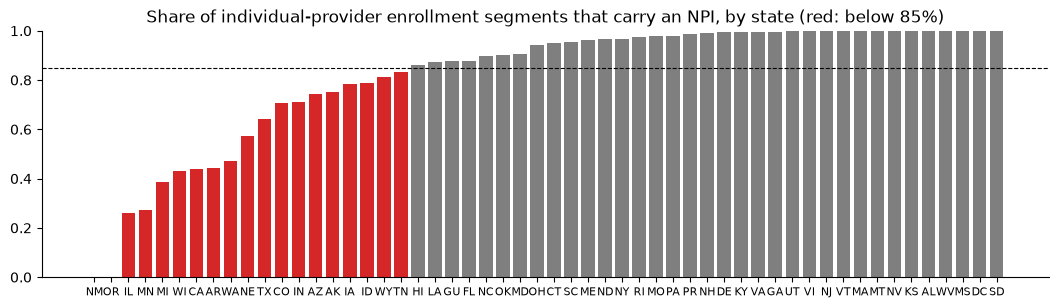

In [2]:
con.execute("""
CREATE TABLE segment_status AS
SELECT status_code, status_desc, count(*) AS segments, count(DISTINCT npi) AS npis
FROM segments GROUP BY ALL ORDER BY segments DESC;

CREATE TABLE state_npi_coverage AS      -- the share of individual-provider segments that carry a valid NPI, by state
SELECT state, count(*) AS individual_segments,
       avg(coalesce(npi SIMILAR TO '1[0-9]{9}', false)::INT) AS npi_share
FROM segments WHERE provider_type = '03'
GROUP BY state;
""")
print("{:,} segments, {:,} with a valid NPI, {:,} distinct NPIs, {} states and territories".format(
    *con.sql("SELECT count(*), count(*) FILTER (WHERE npi SIMILAR TO '1[0-9]{9}'), count(DISTINCT npi), count(DISTINCT state) FROM segments").fetchone()))
print("start dates from", *con.sql("SELECT min(enrl_start), max(enrl_start) FROM segments WHERE enrl_start > DATE '1950-01-01'").fetchone())
display(con.table("segment_status").df().head(12).set_index("status_code"))
cov = con.table("state_npi_coverage").df().sort_values("npi_share")
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.bar(cov.state, cov.npi_share, color=np.where(cov.npi_share < 0.85, "tab:red", "tab:gray"))
ax.axhline(0.85, color="k", lw=0.8, ls="--"); ax.set_ylim(0, 1)
ax.set_title("Share of individual-provider enrollment segments that carry an NPI, by state (red: below 85%)")
ax.tick_params(axis="x", labelsize=8); plt.show()

## 2. The physicians: five specialties, from NPPES

The study's denominator is active, non-trainee MD/DO physicians in NPPES in cardiology, dermatology, ophthalmology, primary care and psychiatry, counted once per year. We take the July snapshot of each year 2018 to 2024, keep individuals whose primary taxonomy (slot 1 of `provider_taxonomy`) is in the specialty list in [`data/specialty_taxonomy.csv`](data/specialty_taxonomy.csv), and drop anyone with the student taxonomy `390200000X` in any slot. The study's own code list is in its paywalled appendix, so the list here is our reading of the five specialty names; primary care is family medicine, general internal medicine, general practice and general pediatrics.

The practice state comes from the same snapshot. The study instead assigned each physician to the state where they had the most Medicaid encounters, which is only defined for physicians who had some. NPPES gives a state for every physician, which is what a denominator needs.

In [3]:
con.execute("""
CREATE TABLE specialties AS
SELECT specialty, pattern FROM read_csv('data/specialty_taxonomy.csv', all_varchar = true);

CREATE TABLE july AS                 -- one snapshot per study year
SELECT year(as_of_date) AS year, as_of_date
FROM snapshots WHERE month(as_of_date) = 7 AND year(as_of_date) BETWEEN 2018 AND 2024;

CREATE TABLE physician_year AS
SELECT j.year, p.npi, p.practice_state, p.enumeration_date, s.specialty, t.taxonomy_code
FROM july j
JOIN provider p ON p.effective_date <= j.as_of_date AND (p.end_date IS NULL OR p.end_date > j.as_of_date)
JOIN provider_taxonomy t ON t.npi = p.npi AND t.effective_date = p.effective_date AND t.slot = 1
JOIN specialties s ON t.taxonomy_code LIKE s.pattern
WHERE p.entity_type = '1'
  AND p.practice_state IS NOT NULL
  AND NOT EXISTS (SELECT 1 FROM provider_taxonomy x
                  WHERE x.npi = p.npi AND x.effective_date = p.effective_date AND x.taxonomy_code = '390200000X');
""")
counts = con.sql("PIVOT (SELECT year, specialty, count(*) AS n FROM physician_year GROUP BY ALL) ON year USING sum(n) ORDER BY specialty").df().set_index("specialty")
# the study's NPPES counts (its Exhibit 1), for 2019 to 2021
zhu = pd.DataFrame({"2019": [30092, 11696, 18268, 277120, 44647], "2020": [34389, 14507, 22159, 334889, 54977], "2021": [35701, 15494, 23030, 356808, 58123]},
                   index=["cardiology", "dermatology", "ophthalmology", "primary care", "psychiatry"])
display(counts.astype(int))
print("Zhu et al. Exhibit 1, NPPES counts:"); display(zhu)

,2018,2019,2020,2021,2022,2023,2024
specialty,,,,,,,
cardiology,29994,30820,31551,32082,32763,33402,34281
dermatology,13781,14227,14653,15033,15402,15776,16315
ophthalmology,21797,22237,22631,22907,23157,23439,23878
primary care,330776,334980,339503,343076,346644,351093,357887
psychiatry,53166,54194,55208,55932,56668,57651,59105


Zhu et al. Exhibit 1, NPPES counts:


,2019,2020,2021
cardiology,30092,34389,35701
dermatology,11696,14507,15494
ophthalmology,18268,22159,23030
primary care,277120,334889,356808
psychiatry,44647,54977,58123


For 2021 our counts are within four percent of the study's in four specialties and ten percent lower in cardiology, which means a broader cardiology code list on their side. For 2019 the study's counts are a fifth lower than ours in four specialties, and they then rise by a fifth from 2019 to 2020, while the registry's physician stock grew by about one percent a year. The monthly panel shows no such step, so it is in how the yearly NPPES extracts were built, not in the workforce. A monthly history makes the denominator the same object every year.

## 3. Enrollment spells

An "enrolled" physician-state-year in the study is one with twelve months of active enrollment in that state. To get there from the segment file we keep segments with a valid NPI and an active status (codes `01` to `05`: active, active do-not-pay, reinstated, eligibility verification, encounter only), close open segments at the end of 2024, and merge segments of the same NPI and state that overlap or touch into one spell. `01` is kept because Delaware marks most of its physicians that way.

In [4]:
con.execute("""
CREATE TABLE spells AS
WITH active AS (    -- identical segments (a Medicaid and a CHIP row) become one row, so the windows below have no ties to order
    SELECT npi, state, coalesce(enrl_start, DATE '0001-01-01') AS s, coalesce(enrl_end, DATE '2024-12-31') AS e, count(*) AS n
    FROM segments
    WHERE npi SIMILAR TO '1[0-9]{9}' AND status_code IN ('01', '02', '03', '04', '05')
      AND coalesce(enrl_start, DATE '0001-01-01') <= coalesce(enrl_end, DATE '2024-12-31')
    GROUP BY ALL
),
ordered AS (        -- a segment starts a new spell when it begins after everything before it has ended
    SELECT *, max(e) OVER (PARTITION BY npi, state ORDER BY s, e ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING) AS prev_end
    FROM active
),
grouped AS (
    SELECT *, sum(CASE WHEN prev_end IS NULL OR s > prev_end + INTERVAL 1 DAY THEN 1 ELSE 0 END)
                  OVER (PARTITION BY npi, state ORDER BY s, e ROWS UNBOUNDED PRECEDING) AS spell
    FROM ordered
)
SELECT npi, state, min(s) AS s, max(e) AS e, sum(n)::BIGINT AS segments
FROM grouped GROUP BY npi, state, spell;
""")
print("{:,} active segments became {:,} spells for {:,} NPIs".format(
    *con.sql("SELECT sum(segments), count(*), count(DISTINCT npi) FROM spells").fetchone()))
con.sql("SELECT state, count(*) AS spells, round(avg(segments), 1) AS segments_per_spell FROM spells GROUP BY state ORDER BY 3 DESC LIMIT 5").df()

40,015,556 active segments became 8,364,143 spells for 4,274,224 NPIs


,state,spells,segments_per_spell
0,MO,120588,60.0
1,ND,51212,59.3
2,CO,232056,27.7
3,ME,54510,14.6
4,TX,292954,11.5


## 4. Which states can be used

A state is usable when the enrollment file lets us see its physicians in every year. Two screens, both reported: at least 85 percent of the state's individual-provider segments carry an NPI, and in each year 2018 to 2024 at least 40 percent of the state's NPPES primary care physicians have an active spell in the state. The second catches files that start late or are thin in some years: the District of Columbia's segments begin in January 2021, Ohio's in 2019, and Maine's physicians are almost all absent until 2023. The study excluded 21 of 153 state-years for "data quality concerns"; its list is in the appendix we cannot read, so the screens here are our own, and they cost a lot: nineteen states fail the NPI screen, among them California, Texas, Illinois and Michigan.

In [5]:
con.execute("""
CREATE TABLE state_screen AS
WITH matched AS (           -- share of the state's primary care physicians with a spell overlapping the year
    SELECT practice_state AS state, year,
           avg((EXISTS (SELECT 1 FROM spells x WHERE x.npi = py.npi AND x.state = py.practice_state
                        AND x.s <= make_date(py.year, 12, 31) AND x.e >= make_date(py.year, 1, 1)))::INT) AS pcp_enrolled
    FROM physician_year py WHERE specialty = 'primary care'
    GROUP BY ALL
),
by_state AS (
    SELECT state, min(pcp_enrolled) AS pcp_enrolled_worst_year, first(year ORDER BY pcp_enrolled, year) AS worst_year
    FROM matched GROUP BY state
)
SELECT c.state, c.npi_share, m.pcp_enrolled_worst_year, m.worst_year,
       c.npi_share >= 0.85 AND coalesce(m.pcp_enrolled_worst_year, 0) >= 0.40 AS usable
FROM state_npi_coverage c LEFT JOIN by_state m USING (state);

CREATE TABLE usable_states AS
SELECT state FROM state_screen WHERE usable;
""")
screen = con.table("state_screen").df().sort_values("state")
usable = sorted(screen.state[screen.usable])
print(len(usable), "usable states and territories:", " ".join(usable))
print("excluded:", " ".join(sorted(screen.state[~screen.usable])))
screen[~screen.usable].set_index("state").round(2).T.fillna("")

30 usable states and territories: AL CT DE FL GA HI KS KY LA MA MD MO MS MT NC ND NH NJ NV NY OK PA PR RI SC SD UT VA VT WV
excluded: AK AR AZ CA CO DC GU IA ID IL IN ME MI MN NE NM OH OR TN TX VI WA WI WY


state,AK,AR,AZ,CA,CO,DC,GU,IA,ID,IL,IN,ME,MI,MN,NE,NM,OH,OR,TN,TX,VI,WA,WI,WY
npi_share,0.75,0.44,0.74,0.44,0.71,1.0,0.88,0.78,0.79,0.26,0.71,0.96,0.39,0.27,0.57,0.0,0.94,0.0,0.83,0.64,1.0,0.47,0.43,0.81
pcp_enrolled_worst_year,0.64,0.74,0.58,0.76,0.7,0.0,0.12,0.63,0.89,0.68,0.77,0.04,0.79,0.82,0.76,0.0,0.0,0.0,0.89,0.68,0.37,0.76,0.68,0.65
worst_year,2024,2022,2024,2018,2018,2018,2018,2024,2018,2018,2020,2022,2018,2024,2024,2018,2018,2018,2018,2024,2018,2024,2024,2024
usable,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


## 5. Exhibit 1, extended to 2018-2024

Two measures of "enrolled", both on the usable states only.

* **Anywhere in the year**: the physician has an active spell in any usable state that overlaps the year. This is closest to the study, which counted a physician as enrolled if any state had them.
* **Full year, practice state**: an active spell in the physician's NPPES practice state that covers the whole calendar year. This is the study's own definition of its denominator for the ghost shares.

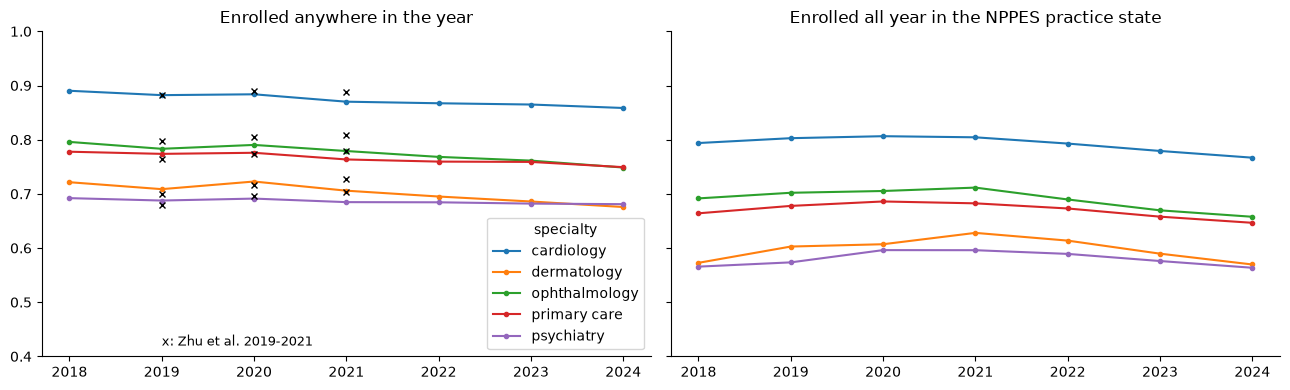

year,2018,2019,2020,2021,2022,2023,2024
specialty,,,,,,,
cardiology,89.0,88.2,88.4,87.0,86.7,86.5,85.9
dermatology,72.2,70.9,72.3,70.6,69.5,68.6,67.6
ophthalmology,79.6,78.3,79.0,77.9,76.8,76.1,74.9
primary care,77.8,77.4,77.6,76.4,76.0,75.9,74.9
psychiatry,69.2,68.8,69.1,68.5,68.4,68.2,68.1


In [6]:
con.execute("""
CREATE TABLE enrollment_by_year AS
SELECT py.year, py.specialty, py.npi, py.practice_state,
       EXISTS (SELECT 1 FROM spells x JOIN usable_states u USING (state)
               WHERE x.npi = py.npi AND x.s <= make_date(py.year, 12, 31) AND x.e >= make_date(py.year, 1, 1)) AS enrolled_anywhere,
       EXISTS (SELECT 1 FROM spells x
               WHERE x.npi = py.npi AND x.state = py.practice_state
                 AND x.s <= make_date(py.year, 1, 1) AND x.e >= make_date(py.year, 12, 31)) AS enrolled_full_year
FROM physician_year py
JOIN usable_states u ON u.state = py.practice_state;
""")
ex1 = con.sql("""
SELECT year, specialty, count(*) AS physicians,
       avg(enrolled_anywhere::INT) AS anywhere, avg(enrolled_full_year::INT) AS full_year_practice_state
FROM enrollment_by_year GROUP BY ALL ORDER BY specialty, year
""").df()
zhu_pct = pd.DataFrame({2019: [88.3, 70.0, 79.7, 76.4, 68.0], 2020: [89.0, 71.6, 80.5, 77.4, 69.6], 2021: [88.8, 72.7, 80.9, 77.9, 70.4]},
                       index=["cardiology", "dermatology", "ophthalmology", "primary care", "psychiatry"]) / 100
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, col, title in ((axes[0], "anywhere", "Enrolled anywhere in the year"), (axes[1], "full_year_practice_state", "Enrolled all year in the NPPES practice state")):
    ex1.pivot(index="year", columns="specialty", values=col).plot(ax=ax, marker="o", ms=3)
    ax.set_title(title); ax.set_xlabel(""); ax.set_ylim(0.4, 1)
for sp in zhu_pct.index:
    axes[0].plot(zhu_pct.columns, zhu_pct.loc[sp], color="k", lw=0, marker="x", ms=5)
axes[0].text(2019, 0.42, "x: Zhu et al. 2019-2021", fontsize=9); axes[1].get_legend().remove()
plt.tight_layout(); plt.show()
(ex1.pivot(index="specialty", columns="year", values="anywhere") * 100).round(1)

The "anywhere" measure reproduces the study's levels for 2019-2021 to within three points in every specialty, on different data and a different set of states. The ranking is the same: cardiology highest, psychiatry lowest. Over the seven years the enrolled share drifts down by three to five points in every specialty except psychiatry, which falls by one. The last point leans on the 2024 segments, the newest and least complete in the file, so the 2024 dip should be read with that in mind.

The "full year, practice state" measure sits 7 to 15 points lower. The gap is physicians who are enrolled somewhere other than where NPPES puts them, or for part of the year.

## 6. What the public spending extract shows about ghosts

The study's ghost share needs a count of patients per physician per year, with zero as a value. The public spending file cannot give that, because a cell (billing NPI, servicing NPI, HCPCS code, month) is in the file only if it has at least 12 patients and 12 claim lines. The histogram starts at 12. A physician who sees eight Medicaid patients a month under three different visit codes is invisible, and so is a physician who sees one a day under one code.

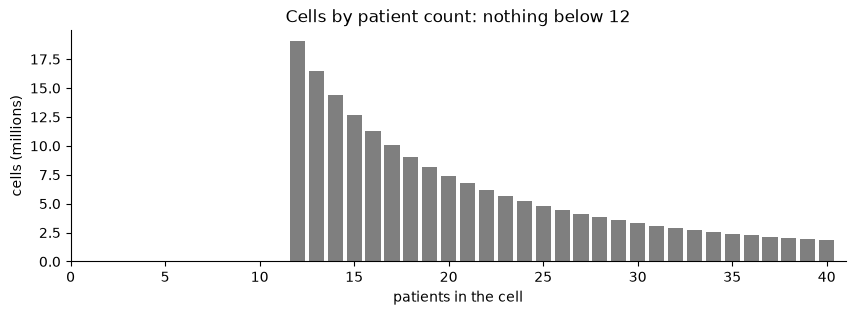

smallest cell: 12 patients, 12 claim lines; 238,015,729 cells in all


In [7]:
hist = con.sql("SELECT patients, count(*) AS cells FROM spending WHERE patients <= 40 GROUP BY 1 ORDER BY 1").df()
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(hist.patients, hist.cells / 1e6, color="tab:gray"); ax.set_xlim(0, 41); ax.set_xlabel("patients in the cell"); ax.set_ylabel("cells (millions)")
ax.set_title("Cells by patient count: nothing below 12"); plt.show()
print("smallest cell: {} patients, {} claim lines; {:,} cells in all".format(*con.sql("SELECT min(patients), min(claim_lines), count(*) FROM spending").fetchone()))

What the file does show is the top of the distribution. For each enrolled physician-year we sum the patients across their evaluation-and-management cells (the five-digit CPT codes `99202` to `99499`, the study's definition, matched on the servicing NPI, or the billing NPI when the servicing NPI is blank). A physician with no visible cell is not necessarily a ghost; a physician with a large visible count is certainly not one. The study's "core" tier, more than 150 unique patients in the year, is the one this file can approximate, with the caveat that summing monthly patient counts over months and codes counts a patient more than once.

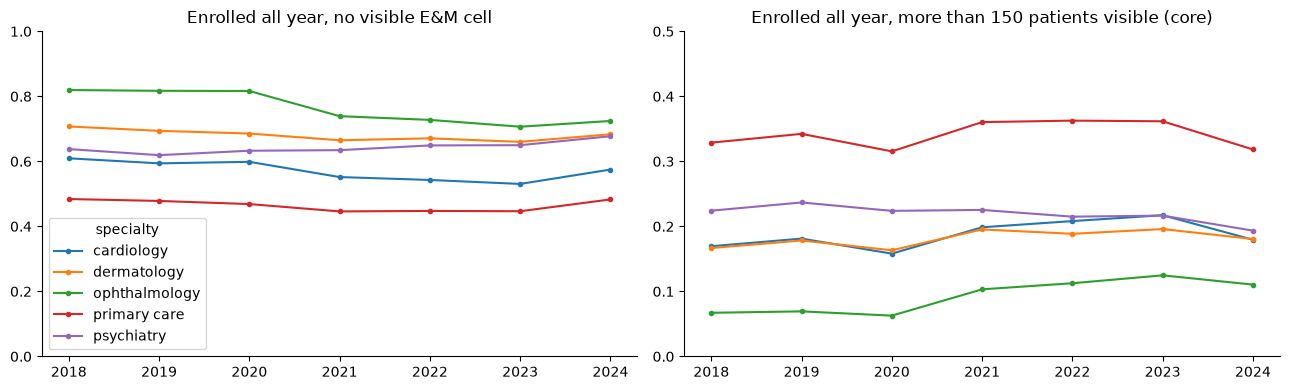

,year,enrolled,no_visible_cell,visible_core
specialty,,,,
cardiology,2021,14129,0.552,0.199
dermatology,2021,4870,0.665,0.195
ophthalmology,2021,8513,0.739,0.103
primary care,2021,117785,0.446,0.360
psychiatry,2021,18185,0.634,0.225


In [8]:
con.execute("""
CREATE TABLE visible_em AS
SELECT coalesce(servicing_npi, billing_npi) AS npi, year(month) AS year,
       sum(patients) AS patient_cell_sum, count(*) AS cells, count(DISTINCT month) AS months
FROM spending
WHERE hcpcs SIMILAR TO '99[2-4][0-9]{2}' AND hcpcs BETWEEN '99202' AND '99499'
  AND coalesce(servicing_npi, billing_npi) IS NOT NULL
GROUP BY ALL;

CREATE TABLE participation AS
SELECT e.year, e.specialty, e.npi, e.enrolled_full_year,
       v.patient_cell_sum, v.months
FROM enrollment_by_year e
LEFT JOIN visible_em v ON v.npi = e.npi AND v.year = e.year;
""")
part = con.sql("""
SELECT year, specialty,
       count(*) FILTER (WHERE enrolled_full_year) AS enrolled,
       avg((patient_cell_sum IS NULL)::INT) FILTER (WHERE enrolled_full_year) AS no_visible_cell,
       avg(coalesce(patient_cell_sum > 150, false)::INT) FILTER (WHERE enrolled_full_year) AS visible_core
FROM participation GROUP BY ALL ORDER BY specialty, year
""").df()
zhu_core = pd.Series({"cardiology": 0.307, "primary care": 0.337}, name="Zhu et al. core share, 2021")
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
part.pivot(index="year", columns="specialty", values="no_visible_cell").plot(ax=axes[0], marker="o", ms=3)
axes[0].set_title("Enrolled all year, no visible E&M cell"); axes[0].set_ylim(0, 1); axes[0].set_xlabel("")
part.pivot(index="year", columns="specialty", values="visible_core").plot(ax=axes[1], marker="o", ms=3)
axes[1].set_title("Enrolled all year, more than 150 patients visible (core)"); axes[1].set_ylim(0, 0.5); axes[1].set_xlabel(""); axes[1].get_legend().remove()
plt.tight_layout(); plt.show()
part[part.year == 2021].set_index("specialty").round(3)

In 2021, between 45 and 74 percent of enrolled physicians, depending on specialty, never reach a 12-patient cell in any month, so the public file cannot tell the study's ghosts (27.7 percent) from its peripheral and standard tiers. A ghost has no cell, so the no-visible-cell share is an upper bound on the ghost share, and the study's figure is within it; the public file can neither confirm nor narrow it. At the top it does better: the visible core share for primary care in 2021, 36 percent, is close to the study's 33.7. Cardiology's, 20 percent, is well below its 30.7, because a cardiologist's visits are spread over more codes and more months and more of them fall under the floor. Over time the visible core share dips in 2020 and recovers, and falls again in 2024, where the claims are the least complete.

## 7. What to be careful about

* **The enrollment file is what states submitted.** Twenty-four states and territories fail the NPI or the yearly match screen and are left out, including California, Texas, Illinois, Michigan, Ohio and the District of Columbia. The usable set is thirty states and territories. It is not the nation, and it is not the study's set either.
* **"Active" is a state's code.** Status codes are state-reported and states use them differently; Delaware's `01 active do not pay` and Louisiana's `05 encounter only` are kept as active. A sensitivity run with `03 active` alone is one line in the `spells` cell.
* **Spells end at the end of 2024** because open segments are closed there. 2024 is the newest and least complete submission year, and T-MSIS marks it preliminary.
* **NPPES is self-reported and lags.** The practice state is the one on the July snapshot, and it changes only when the physician updates the record.
* **The spending file's floor is per cell.** Nothing in this notebook infers a physician's patient count from the file; the visible tier is an upper tier, not a measure of participation.
* **Specialty codes are our list**, not the study's. Counts match to within a few percent, which is enough for shares, not for a reconciliation.

## 8. Where a researcher would go next

* Ask for the study's state exclusion list and specialty codes, and rerun sections 5 and 6 on exactly their set. Everything else is already matched.
* The clean version of the ghost measure is in the restricted T-MSIS files, where the zero is observable. The 2022 to 2024 years extended here are the natural next window for the study's own design.
* Nurse practitioners and physician assistants were excluded from the study because of how they appear on claims. The same spells can be built for taxonomy `363L` and `363A` from the enrollment file.
